# Day 06 – Emotion Recognition in Text (BiLSTM + GloVe vs DistilBERT)

**Goal:** classify English tweets into **6 emotions**: sadness, joy, love, anger, fear, surprise (more detailed than positive/negative).

| Step (task) | What this notebook does |
|---|---|
| 1. Tokenization | Keras `TextVectorization`: words → numbers, padded to the same length |
| 2. Word embeddings | **GloVe** (100-d vectors, pre-trained on Wikipedia) as the embedding layer |
| 3. Model training | **Bidirectional LSTM** reads each tweet forwards and backwards |
| 4. Analysis | Classification report (precision, recall, F1 per emotion), then fine-tune **DistilBERT** and compare |
| Extra | A tiny classic baseline (TF-IDF + Logistic Regression), saved for the Day 19 capstone app |

**Runtime:** GPU recommended (Runtime → Change runtime type → T4 GPU): about 10–15 minutes in total.
On CPU everything still runs; DistilBERT then trains on a smaller sample so it finishes in reasonable time.

## 0. Setup

In [1]:
!pip install -q gensim datasets

import os, re, time, json, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
GPU = len(tf.config.list_physical_devices("GPU")) > 0
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", GPU)
os.makedirs("day06_outputs", exist_ok=True)
RESULTS = {}            # model -> metrics, filled as we go

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: True


## 1. Data: `dair-ai/emotion`
16,000 training, 2,000 validation and 2,000 test tweets, each labelled with one emotion. Already lower-case, no usernames or links.

In [2]:
from datasets import load_dataset
ds = load_dataset("dair-ai/emotion")
LABELS = ds["train"].features["label"].names            # ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
def to_df(split):
    return pd.DataFrame({"text": ds[split]["text"], "label": ds[split]["label"]})
train_df, val_df, test_df = to_df("train"), to_df("validation"), to_df("test")
print("Labels:", LABELS)
print("Train / val / test:", len(train_df), len(val_df), len(test_df))
train_df.assign(emotion=train_df.label.map(lambda i: LABELS[i])).sample(5, random_state=1)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Labels: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
Train / val / test: 16000 2000 2000


,text,label,emotion
2990,i am going to post my training schedule for th...,1,joy
13607,i start to feel like im getting over the death...,2,love
10421,i still feel incredibly listless being in albu...,0,sadness
6238,i can remember i feel especially impressed to ...,5,surprise
6790,i actually prefer peep toe shoes because of it...,5,surprise


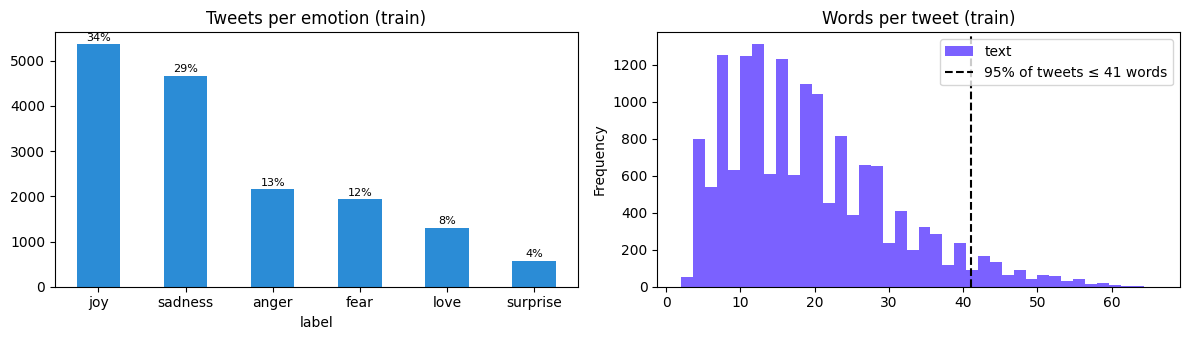

Imbalanced: joy 5362 vs surprise 572 tweets -> we use class weights and look at macro F1, not only accuracy.


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
counts = train_df.label.map(lambda i: LABELS[i]).value_counts()
counts.plot.bar(ax=ax[0], color="#2b8cd6", title="Tweets per emotion (train)", rot=0)
for i, v in enumerate(counts): ax[0].text(i, v + 80, f"{v / len(train_df):.0%}", ha="center", fontsize=8)
lengths = train_df.text.str.split().str.len()
lengths.plot.hist(bins=40, ax=ax[1], color="#7b61ff", title="Words per tweet (train)")
ax[1].axvline(lengths.quantile(0.95), color="k", ls="--", label=f"95% of tweets ≤ {int(lengths.quantile(0.95))} words"); ax[1].legend()
plt.tight_layout(); plt.savefig("day06_outputs/eda.png", dpi=130); plt.show()
print(f"Imbalanced: joy {counts['joy']} vs surprise {counts['surprise']} tweets -> we use class weights and look at macro F1, not only accuracy.")

## 2. Tokenization and padding
`TextVectorization` builds a vocabulary of the 20,000 most common words and turns each tweet into a list of word numbers.
Every list is **padded** (zeros added) or cut to the same length, because the network needs equal-size inputs.

In [4]:
MAX_WORDS, MAX_LEN = 20000, 50
vectorizer = layers.TextVectorization(max_tokens=MAX_WORDS, output_sequence_length=MAX_LEN)
vectorizer.adapt(train_df.text.values)
VOCAB = vectorizer.get_vocabulary()            # index 0 = padding, 1 = unknown word [UNK]
Xtr, Xva, Xte = (vectorizer(d.text.values).numpy() for d in (train_df, val_df, test_df))
ytr, yva, yte = train_df.label.values, val_df.label.values, test_df.label.values
ex = train_df.text.iloc[0]
print("Vocabulary size:", len(VOCAB))
print("Tweet:  ", ex)
print("Numbers:", Xtr[0][:20], "...  (zeros at the end = padding)")
print("Shape:  ", Xtr.shape)

Vocabulary size: 15214
Tweet:   i didnt feel humiliated
Numbers: [  2 140   3 686   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0] ...  (zeros at the end = padding)
Shape:   (16000, 50)


## 3. GloVe word embeddings
GloVe gives every word a vector of 100 numbers learned from Wikipedia, so words with similar meaning have similar vectors
(e.g. *happy* is close to *glad*). We build an **embedding matrix**: row *i* = the GloVe vector of vocabulary word *i*.
If the download fails, the notebook trains **Word2Vec** on our own tweets instead (the task allows either).

In [5]:
EMB_DIM = 100
try:
    import gensim.downloader as api
    wv = api.load("glove-wiki-gigaword-100")           # about 130 MB
    EMB_SOURCE = "GloVe (glove-wiki-gigaword-100)"
except Exception as e:
    print("GloVe download failed, training Word2Vec instead:", str(e)[:80])
    from gensim.models import Word2Vec
    w2v = Word2Vec([t.split() for t in train_df.text], vector_size=EMB_DIM, window=5, min_count=2, workers=2, epochs=10, seed=SEED)
    wv = w2v.wv
    EMB_SOURCE = "Word2Vec trained on the training tweets"

emb_matrix = np.random.normal(0, 0.1, (len(VOCAB), EMB_DIM)).astype("float32")
emb_matrix[0] = 0
found = 0
for i, w in enumerate(VOCAB[2:], start=2):
    if w in wv:
        emb_matrix[i] = wv[w]; found += 1
COVERAGE = found / (len(VOCAB) - 2)
print(f"{EMB_SOURCE}: {found:,} of {len(VOCAB) - 2:,} words found ({COVERAGE:.1%})")
for w in ["happy", "angry", "scared"]:
    if w in wv:
        print(f"  closest to '{w}':", [x for x, _ in wv.most_similar(w, topn=5)])

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe (glove-wiki-gigaword-100): 14,212 of 15,212 words found (93.4%)
  closest to 'happy': ["'m", 'feel', "'re", 'i', "'ll"]
  closest to 'angry': ['furious', 'outraged', 'enraged', 'irate', 'frustrated']
  closest to 'scared': ['frightened', 'afraid', 'tired', 'terrified', 'worried']


## 4. Model 1: Bidirectional LSTM with GloVe
- **Embedding** layer starts from the GloVe matrix and is fine-tuned a little during training.
- **Bidirectional LSTM** reads the tweet left→right and right→left, so it keeps context from both sides (e.g. *"not happy"*).
- Dropout against overfitting, **class weights** so rare emotions (love, surprise) count more, early stopping on validation loss.

In [6]:
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight("balanced", classes=np.arange(len(LABELS)), y=ytr)
CLASS_WEIGHT = dict(enumerate(np.sqrt(cw)))        # softened, so common classes are not hurt too much

def build_bilstm():
    m = keras.Sequential([
        keras.Input(shape=(MAX_LEN,), dtype="int64"),
        layers.Embedding(len(VOCAB), EMB_DIM, embeddings_initializer=keras.initializers.Constant(emb_matrix), mask_zero=True),
        layers.SpatialDropout1D(0.2),
        layers.Bidirectional(layers.LSTM(64)),
        layers.Dropout(0.4),
        layers.Dense(64, activation="relu"),
        layers.Dense(len(LABELS), activation="softmax"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(2e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

bilstm = build_bilstm()
bilstm.summary()
t0 = time.time()
hist = bilstm.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=12, batch_size=64, class_weight=CLASS_WEIGHT, verbose=2,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
LSTM_TIME = time.time() - t0
print(f"BiLSTM training time: {LSTM_TIME / 60:.1f} min")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 100)        │     1,521,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 50, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,614,526 (6.16 MB)

 Trainable params: 1,614,526 (6.16 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
250/250 - 9s - 35ms/step - accuracy: 0.5034 - loss: 1.3024 - val_accuracy: 0.8410 - val_loss: 0.4700
Epoch 2/12
250/250 - 3s - 11ms/step - accuracy: 0.8763 - loss: 0.3539 - val_accuracy: 0.9165 - val_loss: 0.2237
Epoch 3/12
250/250 - 3s - 11ms/step - accuracy: 0.9283 - loss: 0.1875 - val_accuracy: 0.9270 - val_loss: 0.1903
Epoch 4/12
250/250 - 3s - 11ms/step - accuracy: 0.9442 - loss: 0.1407 - val_accuracy: 0.9320 - val_loss: 0.1749
Epoch 5/12
250/250 - 3s - 14ms/step - accuracy: 0.9546 - loss: 0.1072 - val_accuracy: 0.9295 - val_loss: 0.1724
Epoch 6/12
250/250 - 3s - 10ms/step - accuracy: 0.9648 - loss: 0.0907 - val_accuracy: 0.9240 - val_loss: 0.1882
Epoch 7/12
250/250 - 3s - 11ms/step - accuracy: 0.9734 - loss: 0.0707 - val_accuracy: 0.9250 - val_loss: 0.2259
BiLSTM training time: 0.4 min


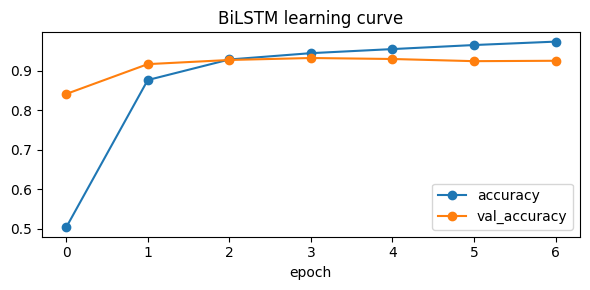

===== BiLSTM + GloVe (test, 2000 tweets) =====
              precision    recall  f1-score   support

     sadness      0.984     0.952     0.968       581
         joy      0.950     0.948     0.949       695
        love      0.830     0.830     0.830       159
       anger      0.925     0.942     0.933       275
        fear      0.918     0.853     0.884       224
    surprise      0.649     0.955     0.773        66

    accuracy                          0.928      2000
   macro avg      0.876     0.913     0.890      2000
weighted avg      0.933     0.928     0.930      2000



In [7]:
pd.DataFrame(hist.history)[["accuracy", "val_accuracy"]].plot(figsize=(6, 3), title="BiLSTM learning curve", marker="o")
plt.xlabel("epoch"); plt.tight_layout(); plt.savefig("day06_outputs/bilstm_curve.png", dpi=130); plt.show()

def evaluate(name, y_pred, seconds, size_mb):
    rep = classification_report(yte, y_pred, target_names=LABELS, digits=3, output_dict=True)
    print(f"===== {name} (test, {len(yte)} tweets) =====")
    print(classification_report(yte, y_pred, target_names=LABELS, digits=3))
    RESULTS[name] = {"accuracy": accuracy_score(yte, y_pred), "macro_f1": f1_score(yte, y_pred, average="macro"),
                     "per_class_f1": {l: rep[l]["f1-score"] for l in LABELS}, "train_seconds": seconds, "size_mb": size_mb,
                     "pred": list(map(int, y_pred))}

lstm_pred = bilstm.predict(Xte, verbose=0).argmax(1)
bilstm.save("day06_outputs/bilstm_glove.keras")
evaluate("BiLSTM + GloVe", lstm_pred, LSTM_TIME, os.path.getsize("day06_outputs/bilstm_glove.keras") / 1e6)

## 5. Model 2: fine-tune DistilBERT (Hugging Face)
DistilBERT is a small Transformer (66M parameters) already pre-trained on a lot of English. We add a classification head and
fine-tune all of it on our tweets. Unlike GloVe (one vector per word), it gives each word a meaning **based on the whole sentence**.

In [8]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "distilbert-base-uncased"
device = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS, BATCH, TOKEN_LEN = (2, 32, 64) if device == "cuda" else (1, 32, 48)
N_TRAIN = len(train_df) if device == "cuda" else min(4000, len(train_df))         # smaller sample on CPU so it finishes in ~15 min
print(f"Device: {device} | epochs {EPOCHS} | training tweets {N_TRAIN}")

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)}).to(device)

def loader(df, shuffle):
    enc = tok(list(df.text), truncation=True, padding="max_length", max_length=TOKEN_LEN, return_tensors="pt")
    return DataLoader(TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(df.label.values)), batch_size=BATCH, shuffle=shuffle)

tr_dl = loader(train_df.sample(N_TRAIN, random_state=SEED), True)
te_dl = loader(test_df, False)
opt = torch.optim.AdamW(bert.parameters(), lr=5e-5, weight_decay=0.01)
steps = EPOCHS * len(tr_dl)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: max(0.0, 1 - s / steps))

t0 = time.time()
bert.train()
for ep in range(EPOCHS):
    total = 0.0
    for i, (ids, mask, y) in enumerate(tr_dl):
        out = bert(input_ids=ids.to(device), attention_mask=mask.to(device), labels=y.to(device))
        out.loss.backward(); opt.step(); sched.step(); opt.zero_grad()
        total += out.loss.item()
        if i % 100 == 0:
            print(f"  epoch {ep + 1} step {i}/{len(tr_dl)} loss {out.loss.item():.3f}")
    print(f"Epoch {ep + 1}: mean loss {total / len(tr_dl):.3f}")
BERT_TIME = time.time() - t0
print(f"DistilBERT fine-tuning time: {BERT_TIME / 60:.1f} min")

bert.eval(); preds = []
with torch.no_grad():
    for ids, mask, _ in te_dl:
        preds.append(bert(input_ids=ids.to(device), attention_mask=mask.to(device)).logits.argmax(-1).cpu().numpy())
bert_pred = np.concatenate(preds)
bert.save_pretrained("day06_outputs/distilbert_emotion"); tok.save_pretrained("day06_outputs/distilbert_emotion")
size = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk("day06_outputs/distilbert_emotion") for f in fs) / 1e6
evaluate("DistilBERT (fine-tuned)" + ("" if device == "cuda" else f", {N_TRAIN} tweets, CPU"), bert_pred, BERT_TIME, size)

Device: cuda | epochs 2 | training tweets 16000


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

... (2 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 step 0/500 loss 1.785
  epoch 1 step 100/500 loss 0.378
  epoch 1 step 200/500 loss 0.198
  epoch 1 step 300/500 loss 0.289
  epoch 1 step 400/500 loss 0.179
Epoch 1: mean loss 0.421
  epoch 2 step 0/500 loss 0.161
  epoch 2 step 100/500 loss 0.286
  epoch 2 step 200/500 loss 0.133
  epoch 2 step 300/500 loss 0.125
  epoch 2 step 400/500 loss 0.080
Epoch 2: mean loss 0.119
DistilBERT fine-tuning time: 3.0 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

===== DistilBERT (fine-tuned) (test, 2000 tweets) =====
              precision    recall  f1-score   support

     sadness      0.969     0.966     0.967       581
         joy      0.946     0.951     0.948       695
        love      0.819     0.855     0.837       159
       anger      0.929     0.945     0.937       275
        fear      0.935     0.839     0.885       224
    surprise      0.707     0.803     0.752        66

    accuracy                          0.929      2000
   macro avg      0.884     0.893     0.888      2000
weighted avg      0.931     0.929     0.930      2000



## 6. Extra: a tiny classic baseline (TF-IDF + Logistic Regression)
Not required by the task, but useful: it trains in seconds on CPU and needs no GPU or TensorFlow. This one is saved as
`emotion_model.joblib` and used as a tool by the **Day 19 capstone** app (fast and light for a free server).

In [9]:
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
t0 = time.time()
tfidf_lr = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(max_iter=2000, C=5))
tfidf_lr.fit(train_df.text, [LABELS[i] for i in ytr])
LR_TIME = time.time() - t0
lr_pred = np.array([LABELS.index(p) for p in tfidf_lr.predict(test_df.text)])
joblib.dump(tfidf_lr, "day06_outputs/emotion_model.joblib")
evaluate("TF-IDF + LogReg (baseline)", lr_pred, LR_TIME, os.path.getsize("day06_outputs/emotion_model.joblib") / 1e6)
info = {"source": "my Day 06 notebook: TF-IDF + Logistic Regression on dair-ai/emotion",
        "test_accuracy": round(RESULTS["TF-IDF + LogReg (baseline)"]["accuracy"], 3),
        "test_macro_f1": round(RESULTS["TF-IDF + LogReg (baseline)"]["macro_f1"], 3), "test_size": len(yte)}
json.dump(info, open("day06_outputs/emotion_model.joblib.json", "w"))

===== TF-IDF + LogReg (baseline) (test, 2000 tweets) =====
              precision    recall  f1-score   support

     sadness      0.892     0.921     0.906       581
         joy      0.849     0.940     0.892       695
        love      0.769     0.629     0.692       159
       anger      0.898     0.829     0.862       275
        fear      0.879     0.781     0.827       224
    surprise      0.708     0.515     0.596        66

    accuracy                          0.863      2000
   macro avg      0.833     0.769     0.796      2000
weighted avg      0.861     0.863     0.859      2000



## 7. Comparison

,accuracy,macro F1,F1 sadness,F1 joy,F1 love,F1 anger,F1 fear,F1 surprise,train time (min),model size (MB)
BiLSTM + GloVe,0.928,0.890,0.968,0.949,0.830,0.933,0.884,0.773,0.4,51.4
DistilBERT (fine-tuned),0.929,0.888,0.967,0.948,0.837,0.937,0.885,0.752,3.0,268.6
TF-IDF + LogReg (baseline),0.863,0.796,0.906,0.892,0.692,0.862,0.827,0.596,0.2,2.4


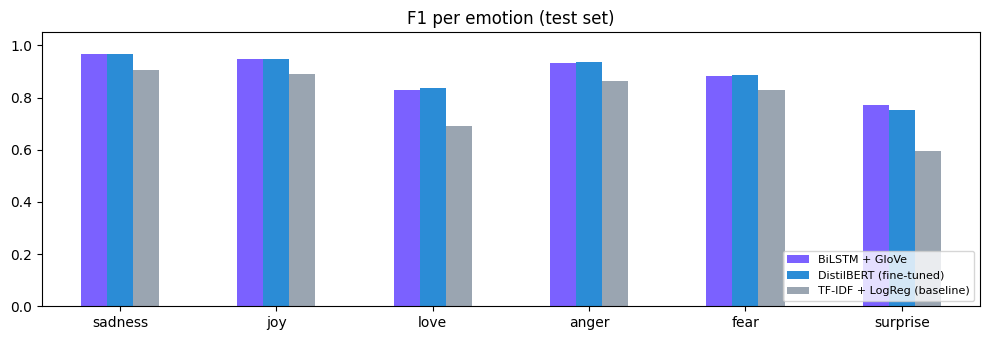

In [10]:
cmp_df = pd.DataFrame({n: {"accuracy": r["accuracy"], "macro F1": r["macro_f1"], **{f"F1 {l}": r["per_class_f1"][l] for l in LABELS},
                           "train time (min)": r["train_seconds"] / 60, "model size (MB)": r["size_mb"]} for n, r in RESULTS.items()}).T
display(cmp_df.style.format("{:.3f}").format("{:.1f}", subset=["train time (min)", "model size (MB)"]).highlight_max(
    subset=["accuracy", "macro F1"], color="#d4f4dd"))
f1 = pd.DataFrame({n: r["per_class_f1"] for n, r in RESULTS.items()})
ax = f1.plot.bar(figsize=(10, 3.5), rot=0, color=["#7b61ff", "#2b8cd6", "#9aa5b1"][:len(RESULTS)], title="F1 per emotion (test set)")
ax.set_ylim(0, 1.05); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("day06_outputs/f1_per_emotion.png", dpi=130); plt.show()

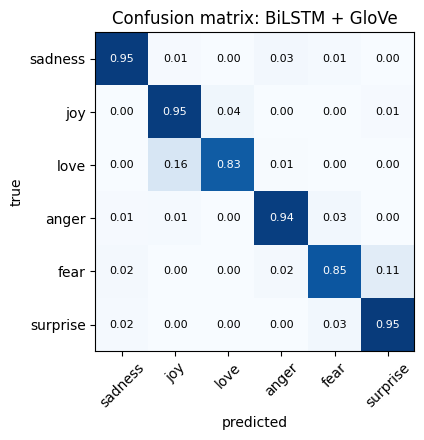

Most common mistakes (true -> predicted, share of that emotion):
  love     -> joy      16%
  fear     -> surprise 11%
  joy      -> love     4%
  surprise -> fear     3%


,text,true,pred
1015,i feel blessed that i have people in my life w...,love,joy
1677,i become someone else and i make random awkwar...,fear,surprise
408,i feel quite passionate about and that is how ...,joy,love
108,i looked at mabel this morning i named my left...,fear,surprise
1780,when i learnt that my best friend had failed t...,anger,joy
531,i feel like i am not accepted here i and bucki...,joy,love


In [11]:
best = max(RESULTS, key=lambda n: RESULTS[n]["macro_f1"])
bp = np.array(RESULTS[best]["pred"])
cm = confusion_matrix(yte, bp, normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(6), LABELS, rotation=45); ax.set_yticks(range(6), LABELS)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix: {best}")
plt.tight_layout(); plt.savefig("day06_outputs/confusion_best.png", dpi=130); plt.show()

off = [(LABELS[i], LABELS[j], cm[i, j]) for i in range(6) for j in range(6) if i != j]
print("Most common mistakes (true -> predicted, share of that emotion):")
for t, p, v in sorted(off, key=lambda x: -x[2])[:4]:
    print(f"  {t:8s} -> {p:8s} {v:.0%}")
wrong = test_df.assign(pred=[LABELS[i] for i in bp], true=[LABELS[i] for i in yte])
mist = wrong[wrong.pred != wrong.true]
display(mist.sample(min(6, len(mist)), random_state=1)[["text", "true", "pred"]])

In [12]:
# Save results (small files) and download them. The DistilBERT folder (~260 MB) stays in Colab unless you copy it to Drive.
summary = {n: {k: v for k, v in r.items() if k != "pred"} for n, r in RESULTS.items()}
summary["_info"] = {"embeddings": EMB_SOURCE, "glove_coverage": COVERAGE, "max_len": MAX_LEN, "gpu": GPU}
json.dump(summary, open("day06_outputs/results.json", "w"), indent=1, default=float)
if os.path.exists("day06_results.zip"): os.remove("day06_results.zip")
os.system("cd day06_outputs && zip -qr ../day06_results.zip . -x 'distilbert_emotion/*'")      # everything except the big DistilBERT folder
print("Saved day06_results.zip (results, plots, BiLSTM model, emotion_model.joblib for the capstone)")
try:
    from google.colab import files
    files.download("day06_results.zip")
except Exception:
    pass

Saved day06_results.zip (results, plots, BiLSTM model, emotion_model.joblib for the capstone)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>